<a href="https://colab.research.google.com/github/Ambartheanalyst-blip/Assignment-1/blob/main/Assigment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 4: Salary Data Analysis

data analysis on faculty salaries using pandas and matplotlib. We will explore the dataset, clean and wrangle the data, generate key visualizations, and draw objective conclusions based on the empirical results.

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

In [31]:
url = "https://raw.githubusercontent.com/CunyLaguardiaDataAnalytics/datasets/master/Salaries.csv"
df = pd.read_csv(url)

In [32]:
df.head()

,Unnamed: 0,rank,discipline,yrs.since.phd,yrs.service,sex,salary
0,1,Prof,B,19,18,Male,139750
1,2,Prof,B,20,16,Male,173200
2,3,AsstProf,B,4,3,Male,79750
3,4,Prof,B,45,39,Male,115000
4,5,Prof,B,40,41,Male,141500


In [33]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 397
Number of columns: 7


In [34]:
print(df.columns.tolist())

['Unnamed: 0', 'rank', 'discipline', 'yrs.since.phd', 'yrs.service', 'sex', 'salary']


In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Unnamed: 0     397 non-null    int64 
 1   rank           397 non-null    object
 2   discipline     397 non-null    object
 3   yrs.since.phd  397 non-null    int64 
 4   yrs.service    397 non-null    int64 
 5   sex            397 non-null    object
 6   salary         397 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 21.8+ KB


In [36]:
df.describe()

,Unnamed: 0,yrs.since.phd,yrs.service,salary
count,397.000000,397.000000,397.000000,397.000000
mean,199.000000,22.314861,17.614610,113706.458438
std,114.748275,12.887003,13.006024,30289.038695
min,1.000000,1.000000,0.000000,57800.000000
25%,100.000000,12.000000,7.000000,91000.000000
50%,199.000000,21.000000,16.000000,107300.000000
75%,298.000000,32.000000,27.000000,134185.000000
max,397.000000,56.000000,60.000000,231545.000000


In [39]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Unnamed: 0       0
rank             0
discipline       0
yrs.since.phd    0
yrs.service      0
sex              0
salary           0
dtype: int64


In [40]:
rows_before = df.shape[0]
df_clean = df.dropna()
rows_after = df_clean.shape[0]
rows_removed = rows_before - rows_after

print(f"Rows before handling missing values: {rows_before}")
print(f"Rows after handling missing values: {rows_after}")
print(f"Rows removed: {rows_removed} (Zero rows were removed because there are no missing values.)")

# Remove the Unnamed: 0 index column if it exists
if 'Unnamed: 0' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Unnamed: 0'])
    print("Removed Unnamed: 0 column.")

Rows before handling missing values: 397
Rows after handling missing values: 397
Rows removed: 0 (Zero rows were removed because there are no missing values.)
Removed Unnamed: 0 column.


In [41]:
df_clean = df_clean.rename(columns={
    'rank': 'academic_rank',
    'yrs.since.phd': 'years_since_phd',
    'yrs.service': 'years_of_service'
})
print("Renamed columns:", df_clean.columns.tolist())

Renamed columns: ['academic_rank', 'discipline', 'years_since_phd', 'years_of_service', 'sex', 'salary']


In [42]:
salary_subset = df_clean[['academic_rank', 'discipline', 'years_since_phd', 'years_of_service', 'sex', 'salary']]
print("Salary subset successfully created:")
print(salary_subset.head())

print("\n--- Overall Salary Summaries ---")
overall_mean = salary_subset['salary'].mean()
overall_median = salary_subset['salary'].median()
print(f"Overall Mean Salary: ${overall_mean:,.2f}")
print(f"Overall Median Salary: ${overall_median:,.2f}")

print("\n--- Salary by Academic Rank ---")
print(salary_subset.groupby('academic_rank')['salary'].agg(['mean', 'median']).round(2))

print("\n--- Salary by Sex ---")
print(salary_subset.groupby('sex')['salary'].agg(['mean', 'median']).round(2))

Salary subset successfully created:
  academic_rank discipline  years_since_phd  years_of_service   sex  salary
0          Prof          B               19                18  Male  139750
1          Prof          B               20                16  Male  173200
2      AsstProf          B                4                 3  Male   79750
3          Prof          B               45                39  Male  115000
4          Prof          B               40                41  Male  141500

--- Overall Salary Summaries ---
Overall Mean Salary: $113,706.46
Overall Median Salary: $107,300.00

--- Salary by Academic Rank ---
                    mean    median
academic_rank                     
AssocProf       93876.44   95626.5
AsstProf        80775.99   79800.0
Prof           126772.11  123321.5

--- Salary by Sex ---
             mean    median
sex                        
Female  101002.41  103750.0
Male    115090.42  108043.0


### Visualization 1: Average Salary by Academic Rank
The bar chart below displays the average salary across different academic ranks.

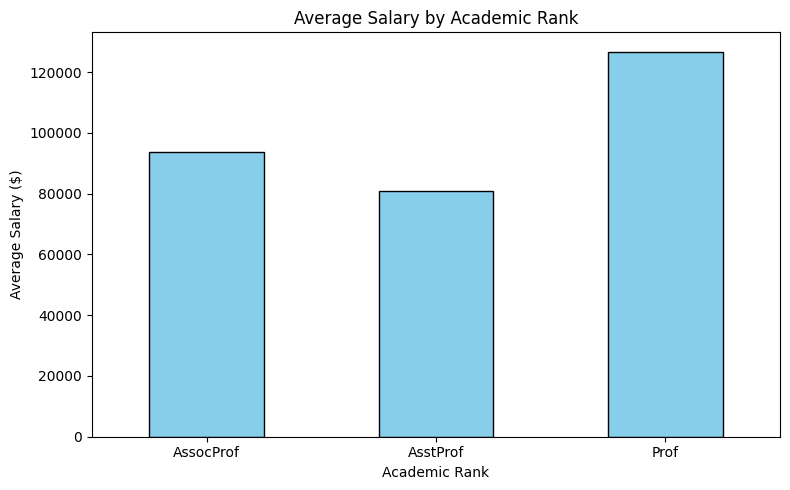

In [43]:
avg_salary_rank = salary_subset.groupby('academic_rank')['salary'].mean()

plt.figure(figsize=(8, 5))
avg_salary_rank.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Average Salary by Academic Rank')
plt.xlabel('Academic Rank')
plt.ylabel('Average Salary ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Professors have the highest average salary in this dataset, followed by Associate Professors and Assistant Professors. This is a descriptive comparison and does not explain why the salary differences exist.

### Visualization 2: Median Salary by Sex
The bar chart below compares the median salary between male and female faculty members.

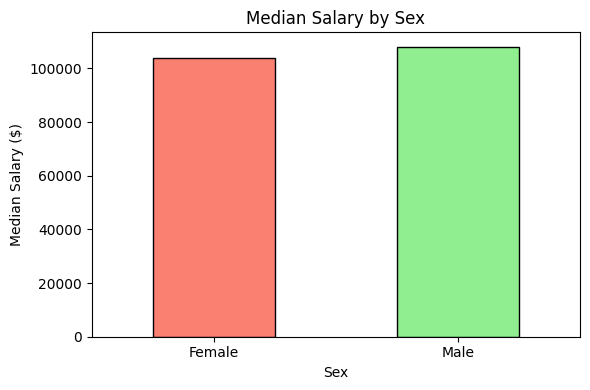

In [44]:
median_salary_sex = salary_subset.groupby('sex')['salary'].median()

plt.figure(figsize=(6, 4))
median_salary_sex.plot(kind='bar', color=['salmon', 'lightgreen'], edgecolor='black')
plt.title('Median Salary by Sex')
plt.xlabel('Sex')
plt.ylabel('Median Salary ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The chart compares median salary across the groups in the sex column. The displayed difference is descriptive and does not establish what caused the difference.

In [45]:
# Cell left blank to remove the years of service vs salary scatter plot

In [46]:
overall_mean_salary = salary_subset["salary"].mean()
overall_median_salary = salary_subset["salary"].median()
average_salary_by_rank = (
    salary_subset.groupby("academic_rank")["salary"].mean()
)
median_salary_by_sex = (
    salary_subset.groupby("sex")["salary"].median()
)
highest_paid_rank = average_salary_by_rank.idxmax()
highest_rank_average = average_salary_by_rank.max()

print(f"Overall mean salary: ${overall_mean_salary:,.2f}")
print(f"Overall median salary: ${overall_median_salary:,.2f}")
print(f"Highest-paid academic rank: {highest_paid_rank}")
print(f"Average salary for {highest_paid_rank}: ${highest_rank_average:,.2f}")
print("\nMedian salary by sex:")
print(median_salary_by_sex)

Overall mean salary: $113,706.46
Overall median salary: $107,300.00
Highest-paid academic rank: Prof
Average salary for Prof: $126,772.11

Median salary by sex:
sex
Female    103750.0
Male      108043.0
Name: salary, dtype: float64


### Conclusions

Overall Mean Salary is $113,706.46

Overall Median Salary is $107,300.00.

Full Professors (Prof) have the highest average salary.

The salary-by-sex results show a descriptive difference, but this analysis does not establish why the salary differences exist.